In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import os
import math
import numpy as np

import sys
sys.path.append('../../bgc-analysis')
from db_api import get_metadata_all
from  calc_sensor import pH_sbe, o2_sbe
sys.path.clear
sys.path.append('C:/Users/athay/OneDrive/Documents/Repositories/test-analysis')
from get_cal_sn import get_cal

In [2]:
lastdate = '20260424'  # SET AS THE LAST DAY THAT THE SPECIFIC FLOW THROUGH TEST WAS RUNNING


In [3]:
root = r"G://Shared drives//WHOI Argo//BGC//Float Tracking//flow_through_data//" + str(lastdate) + "//" # WHERE TO GET THE DATA FROM
files = [x for x in os.listdir(root) if x.endswith(".pkl")] # GETTING ALL pkl FILES

In [4]:
# SETTING UP DATAFRAME

data = pd.DataFrame(columns=['DATE', 'SN', 'PRES', 'TEMP', 'PSAL', 'O2_PHASE_DELAY',
       'O2_TEMPERATURE_VOLTAGE', 'MCOMS1', 'MCOMS2', 'MCOMS3', 'PH_VRS1', 'PH_VRS', 'PH_VK', 'PHIB', 'PHIK', 'PHVIN', 'PHVOUT', 'NITRATE'])
#ADDING DATA FROM ALL FILES INTO ONE BIG DATAFRAME
for file in files:
    data = pd.concat([data,pd.read_pickle(root+'/'+file)])
data = data.sort_values('DATE')
data['DATE'] = data['DATE'].dt.round('1s')
data = data.reset_index()
print(data)


     index                DATE    SN  PRES     TEMP     PSAL  O2_PHASE_DELAY  \
0        0 2026-04-24 07:24:50  1758   0.1  18.9324  31.6954          17.515   
1        1 2026-04-24 07:26:20  1758   0.1  18.9507  31.6994          17.510   
2        0 2026-04-24 07:26:44  1755  -0.2  18.9607  31.6609          17.626   
3        0 2026-04-24 07:26:54  1660  -0.1  18.9532  31.7258          17.586   
4        2 2026-04-24 07:27:48  1758   0.1  18.9697  31.7026          17.501   
..     ...                 ...   ...   ...      ...      ...             ...   
125     41 2026-04-24 08:26:50  1755  -0.2  19.6798  31.7495          17.579   
126     41 2026-04-24 08:26:59  1660  -0.1  19.6834  31.7452          17.533   
127     43 2026-04-24 08:27:54  1758   0.0  19.6979  31.7416          17.459   
128     42 2026-04-24 08:28:18  1755  -0.2  19.6974  31.7498          17.583   
129     42 2026-04-24 08:28:27  1660  -0.2  19.6981  31.7446          17.530   

     O2_TEMPERATURE_VOLTAGE  MCOMS1  MC

In [5]:
# SPLIT UP DATA BY FLOAT AND CALCULATE PH AND OXYGEN 

fnum = []
for sn in data.SN.unique():
    sn = str(sn)
    cal = get_cal(sn)
    sub = data.loc[data.SN == sn,:]
    #PH
    PH_FREE, data.loc[data.SN ==sn, 'PH_TOTAL'] = pH_sbe(cal['TRANSISTOR_PH']['PREDEPLOYMENT_CALIB_COEFFICIENT'],sub.PH_VRS, sub.PRES, sub.TEMP, sub.PSAL)
    #Oxygen
    data.loc[data.SN==sn, 'DOXY'] = (o2_sbe(cal['OPTODE_DOXY']['PREDEPLOYMENT_CALIB_COEFFICIENT'], sub.O2_PHASE_DELAY, sub.O2_TEMPERATURE_VOLTAGE, sub.PRES, sub.TEMP, sub.PSAL)[0])
    fnum.append(sn)


{'F0': -1.413711, 'F1': 3.958793e-06, 'F2': 2.661045e-09, 'F3': -1.07423e-11, 'F4': 1.143362e-14, 'F5': -5.232202e-18, 'F6': 8.868853000000001e-22, 'F7': 0.0, 'F8': 0.0, 'F9': 0.0, 'K0': -1.413945, 'F10': 0.0, 'F11': 0.0, 'F12': 0.0, 'K2f0': -0.0009685949, 'K2f1': -1.785036e-08, 'K2f2': 1.571964e-11, 'K2f3': -4.501894e-15}
{'F0': -1.425422, 'F1': 2.111742e-05, 'F2': -3.680736e-08, 'F3': 3.86497e-11, 'F4': -2.339034e-14, 'F5': 7.492171e-18, 'F6': -9.770935e-22, 'F7': 0.0, 'F8': 0.0, 'F9': 0.0, 'K0': -1.425714, 'F10': 0.0, 'F11': 0.0, 'F12': 0.0, 'K2f0': -0.0009683487, 'K2f1': -3.33752e-08, 'K2f2': 2.282833e-11, 'K2f3': -5.288789e-15}
{'F0': -1.416374, 'F1': 2.207804e-05, 'F2': -3.358585e-08, 'F3': 2.81181e-11, 'F4': -1.247388e-14, 'F5': 2.675945e-18, 'F6': -1.9809270000000002e-22, 'F7': 0.0, 'F8': 0.0, 'F9': 0.0, 'K0': -1.417259, 'F10': 0.0, 'F11': 0.0, 'F12': 0.0, 'K2f0': -0.0009688258, 'K2f1': -5.443285e-08, 'K2f2': 3.958606e-11, 'K2f3': -9.93239e-15}


In [6]:
data.to_excel('G://Shared drives/WHOI Argo/BGC/Float Tracking/flow_through_results/'  + lastdate + '_calcs_' + ".xlsx")


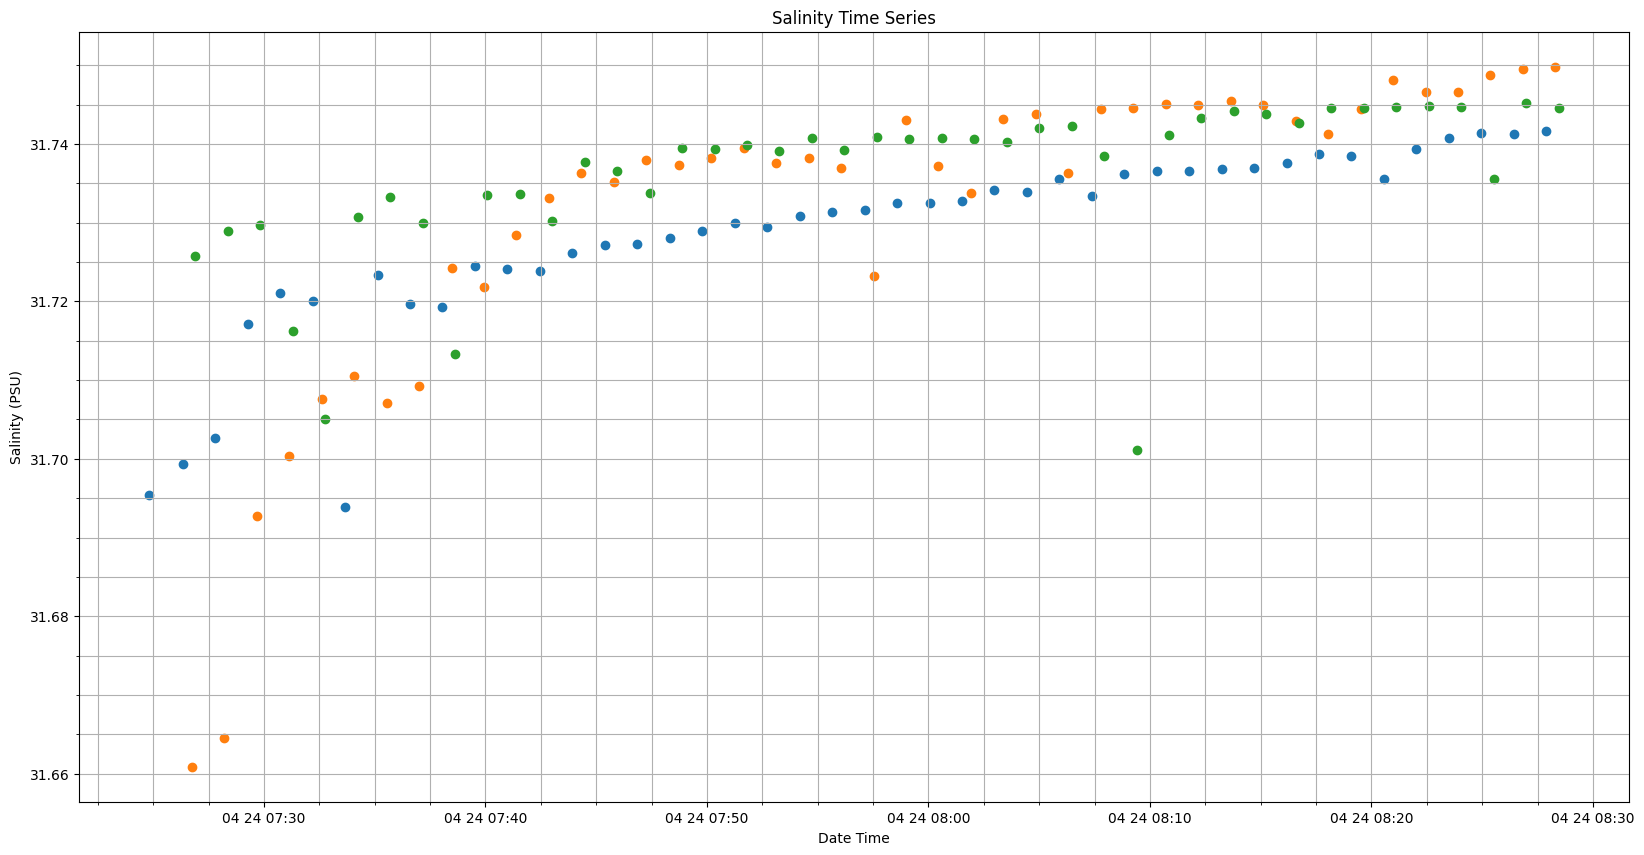

In [7]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['PSAL'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('Salinity Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('Salinity (PSU)')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

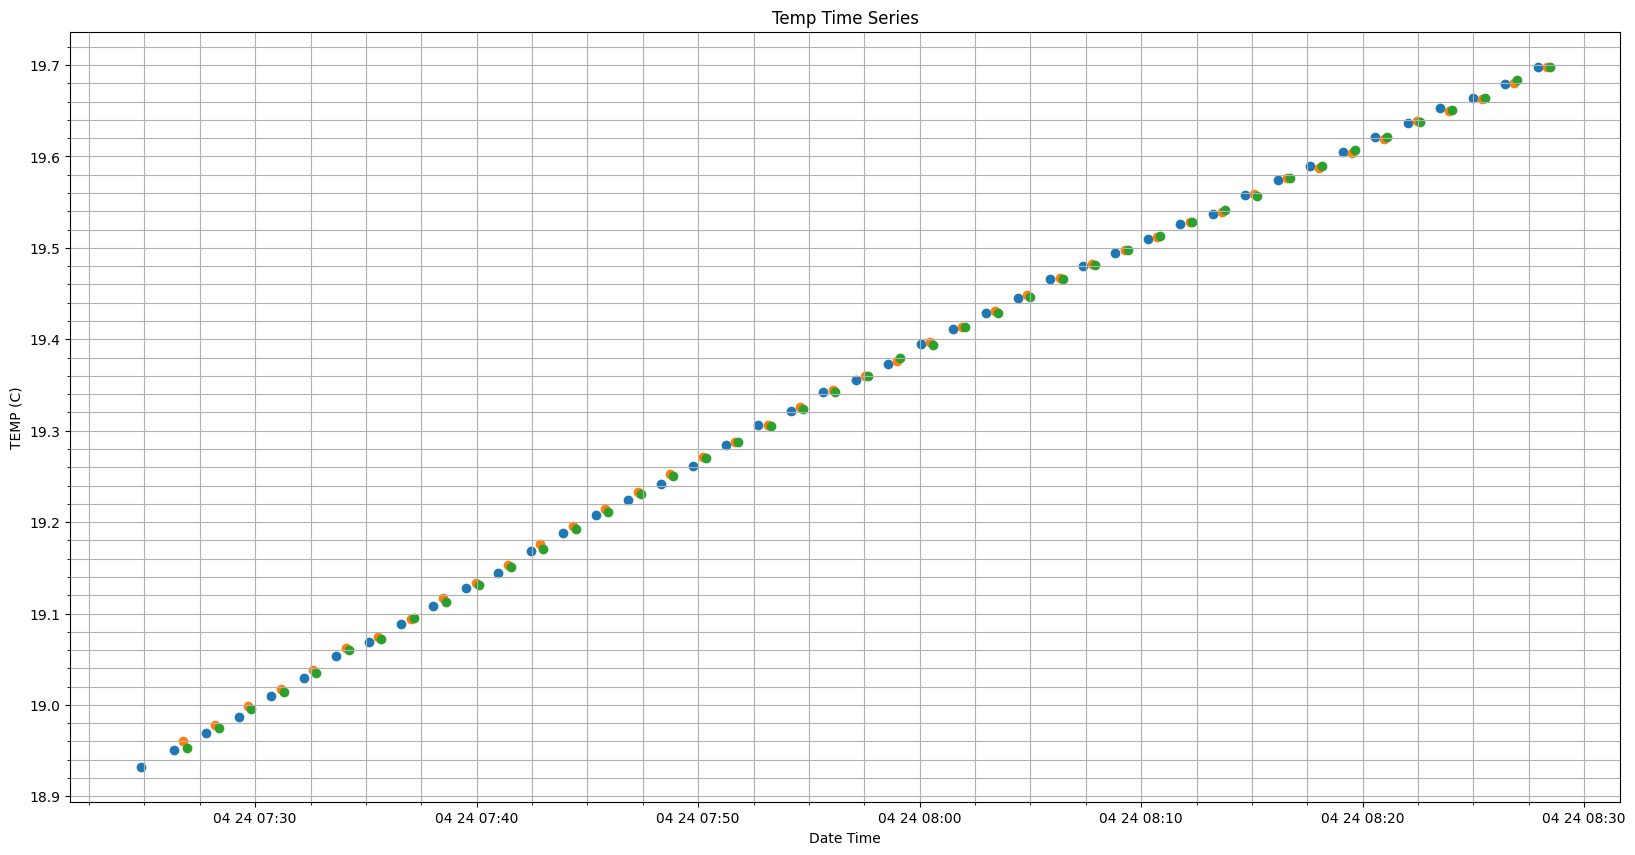

In [8]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['TEMP'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('Temp Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('TEMP (C)')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

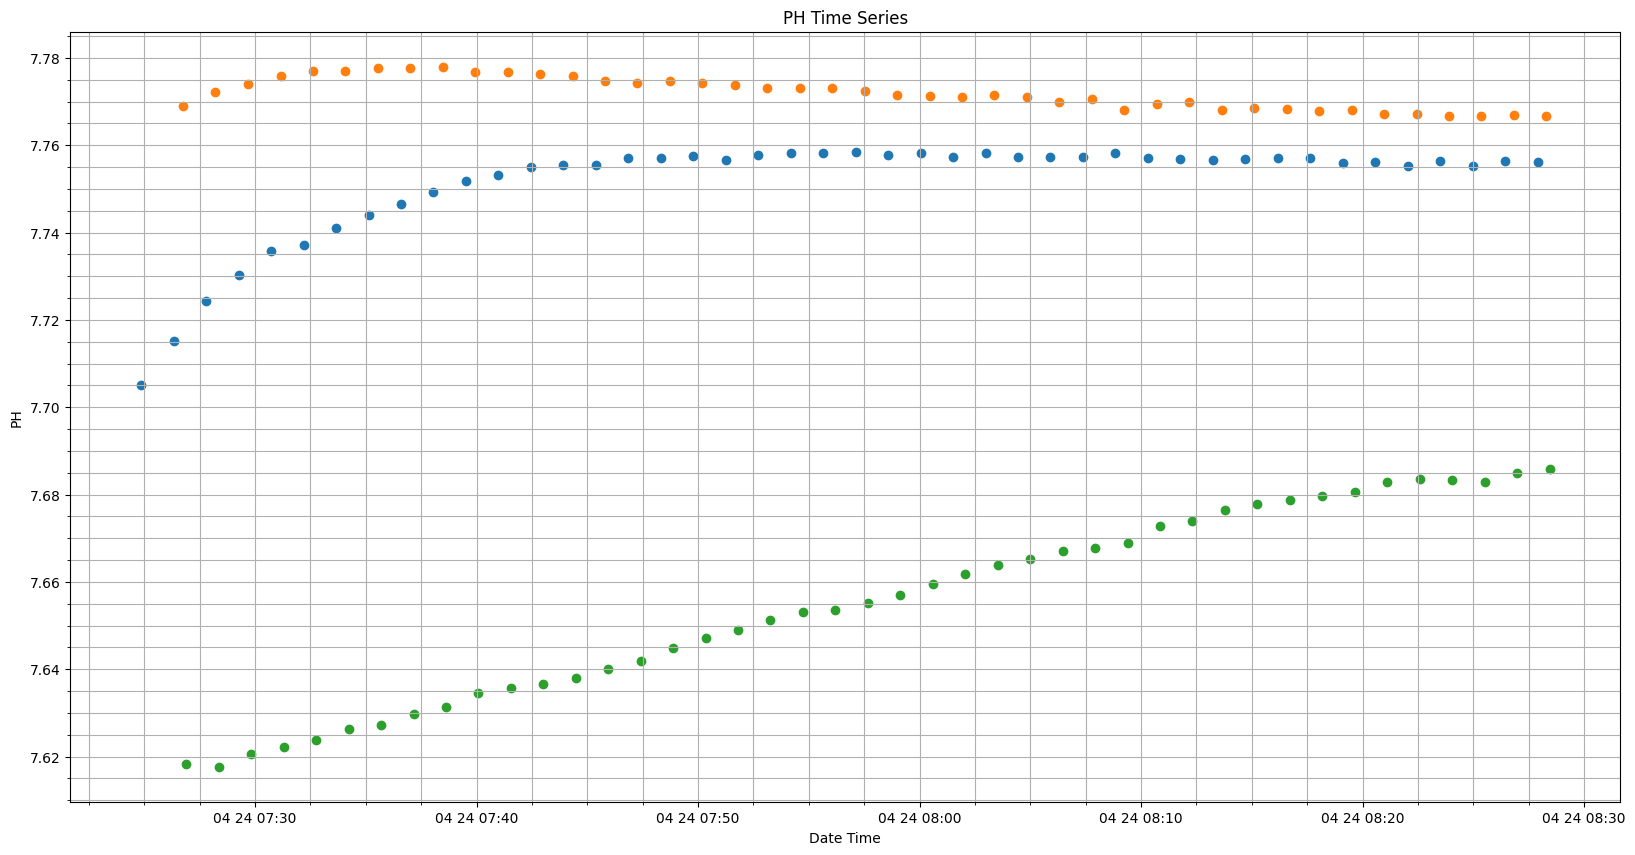

In [9]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['PH_TOTAL'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3]], loc = 'upper left')
pltt.set_title('PH Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('PH')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

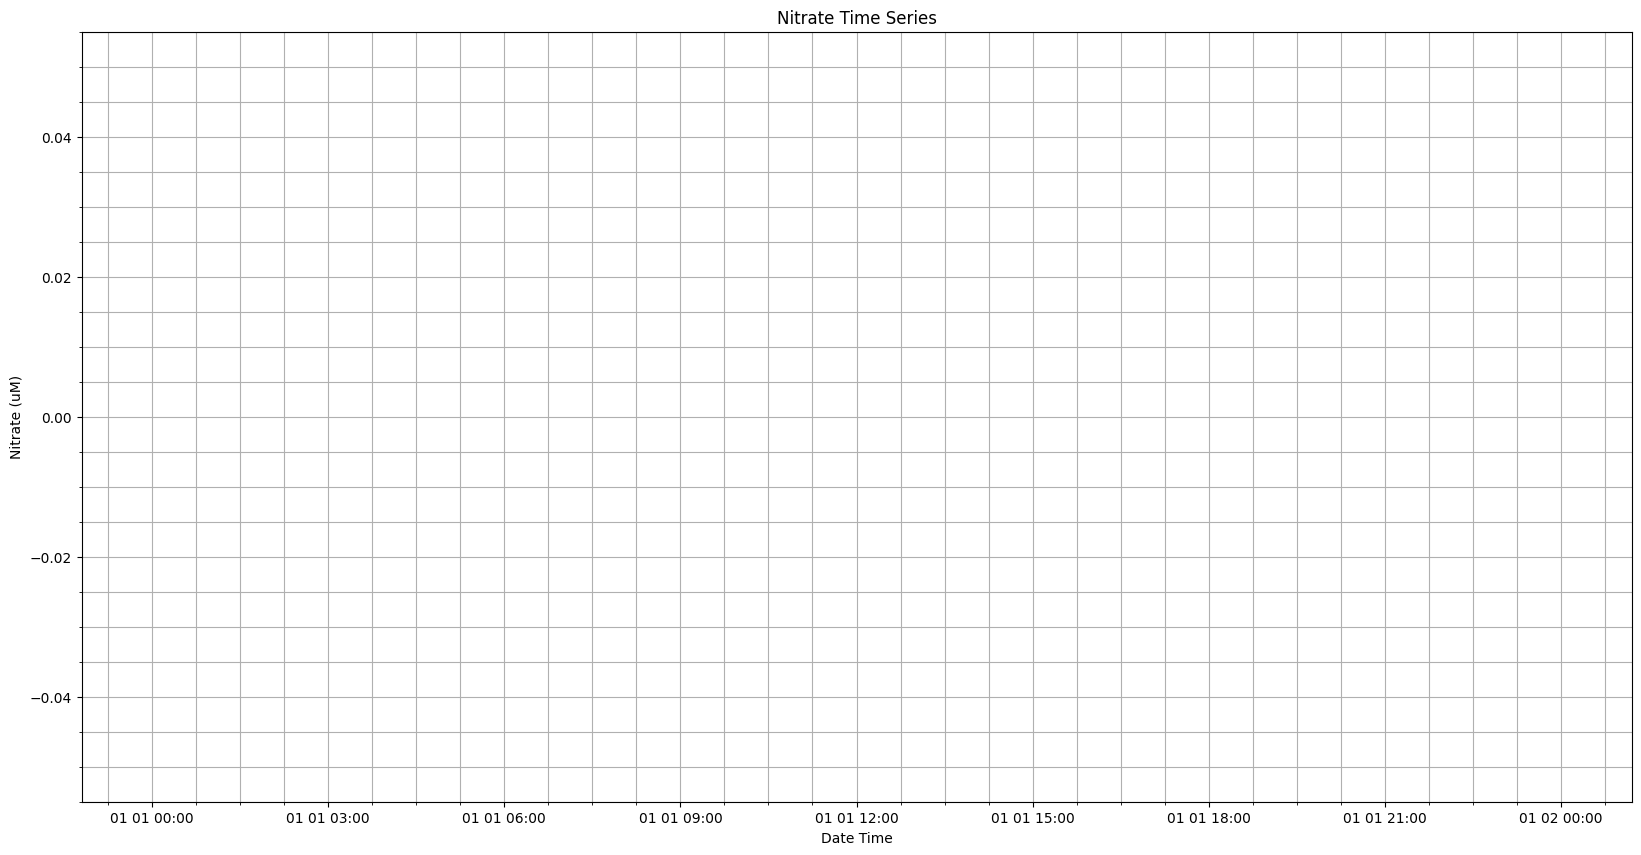

In [10]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['NITRATE'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('Nitrate Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('Nitrate (uM)')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

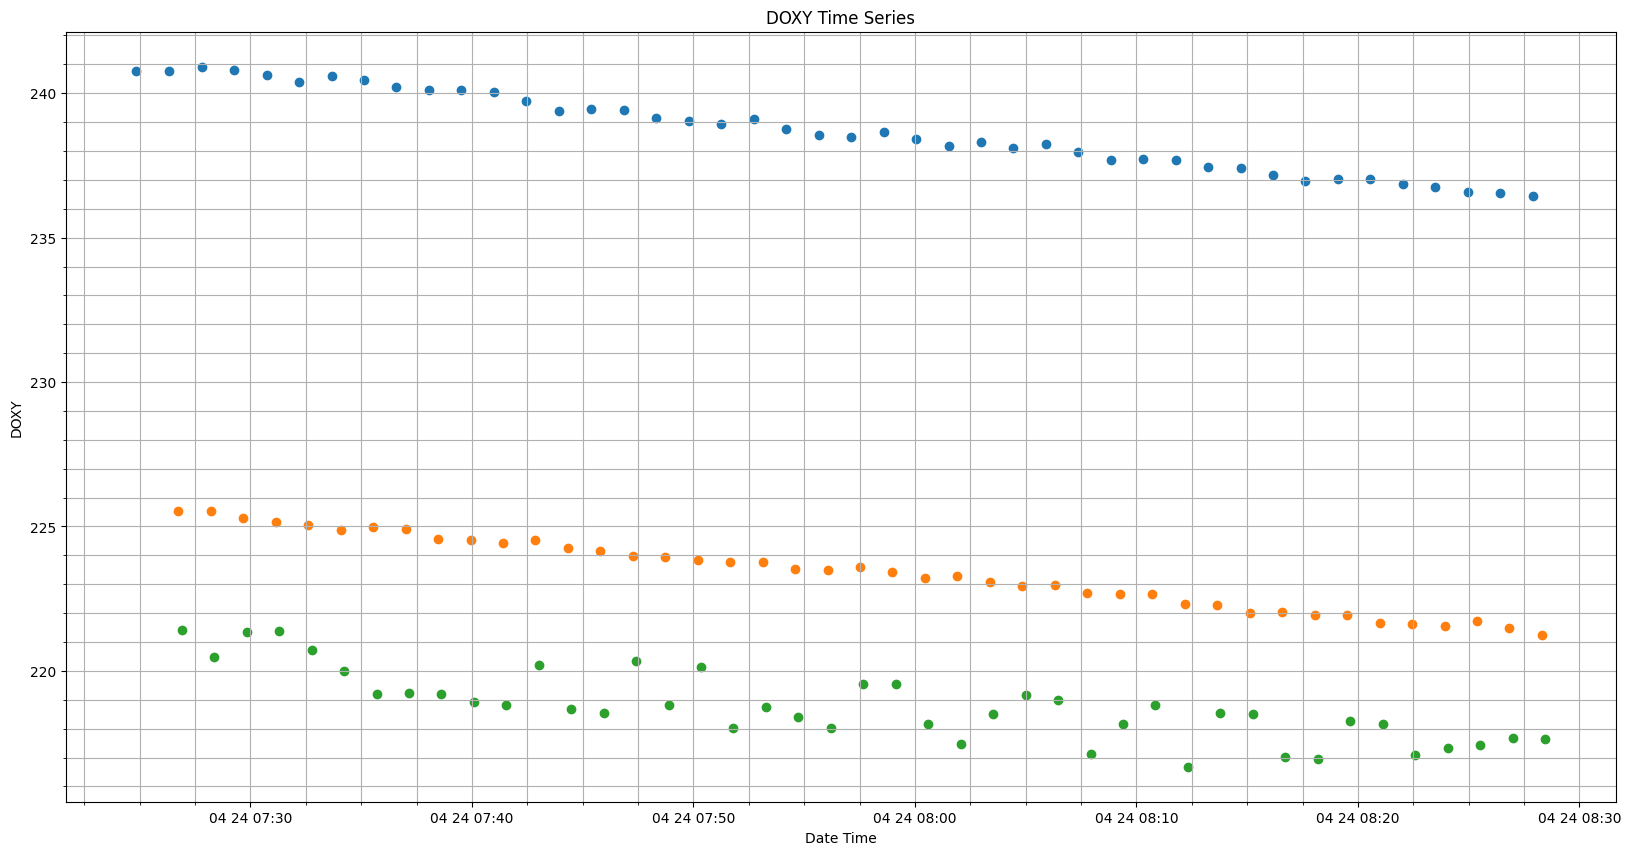

In [11]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['DOXY'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('DOXY Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('DOXY')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')